In [153]:
import os

os.environ["PETSC_DIR"] = "/home/victorcunha/firedrake-install/petsc-src/petsc"
os.environ["PETSC_ARCH"] = "arch-firedrake-default"

import firedrake as fd
from firedrake import FunctionSpace
import gmsh
import numpy as np
import matplotlib.pyplot as plt
from firedrake.pyplot import triplot
import numpy as np
from itertools import permutations
from scipy.sparse.linalg import spsolve

In [154]:
Nx, Ny = 2, 2
Lx, Ly = 1.0, 1.0
msh = fd.RectangleMesh(Nx, Ny, Lx, Ly, quadrilateral=False)
conectividade = msh.coordinates.cell_node_map().values # 1. Extrair a tabela de conectividade (mapeamento de células para nós)
coordenadas_vertices = msh.coordinates.dat.data_ro

In [155]:

# 2. Exibir informações gerais e as primeiras linhas
print(f"Formato da tabela de conectividade: {conectividade.shape}")
print(f"(Temos {conectividade.shape[0]} elementos e cada um possui {conectividade.shape[1]} vértices)\n")

# Exibir os primeiros 10 elementos como exemplo
print("Elemento ID | Vértices Globais")
print("-----------------------------")
for i in range( len(conectividade)):
    print(f"Elemento {i:02d}  | {conectividade[i]}")

print("-----------------------------")

print("Vértice ID | Coordenadas (X, Y)")
print("---------------------------")
for i in range(len(coordenadas_vertices)):
    print(f"Vértice {i:02d}  | {coordenadas_vertices[i]}")

Formato da tabela de conectividade: (8, 3)
(Temos 8 elementos e cada um possui 3 vértices)

Elemento ID | Vértices Globais
-----------------------------
Elemento 00  | [0 1 2]
Elemento 01  | [1 2 3]
Elemento 02  | [2 3 4]
Elemento 03  | [1 3 5]
Elemento 04  | [3 4 6]
Elemento 05  | [3 5 7]
Elemento 06  | [3 6 7]
Elemento 07  | [6 7 8]
-----------------------------
Vértice ID | Coordenadas (X, Y)
---------------------------
Vértice 00  | [0. 0.]
Vértice 01  | [0.  0.5]
Vértice 02  | [0.5 0. ]
Vértice 03  | [0.5 0.5]
Vértice 04  | [1. 0.]
Vértice 05  | [0. 1.]
Vértice 06  | [1.  0.5]
Vértice 07  | [0.5 1. ]
Vértice 08  | [1. 1.]


In [156]:
def gerar_malha_2d(lx=1.0, ly=1.0, nx=5, ny=5):
    """
    Gera uma malha triangular estruturada com o Firedrake.

    nx e ny são o número de divisões nas direções x e y.
    Retorna:
        nos: array (número de nós, 2), com as coordenadas (x, y);
        elementos: array (número de triângulos, 3), com os índices dos nós.
    """
    msh = fd.RectangleMesh( nx, ny, lx, ly, quadrilateral=False )
    nos = np.array(msh.coordinates.dat.data_ro, copy=True)
    elementos = np.array(msh.coordinates.cell_node_map().values, dtype=int, copy=True)

    return np.array(nos), np.array(elementos)

In [157]:
nos, elementos = gerar_malha_2d(
    lx=1.0,
    ly=1.0,
    nx=2,
    ny=2
)

print("Nós:")
print(nos)

print("\nConectividade:")
print(elementos)

print("\nFormato de nos:", nos.shape)
print("Formato de elementos:", elementos.shape)

Nós:
[[0.  0. ]
 [0.  0.5]
 [0.5 0. ]
 [0.5 0.5]
 [1.  0. ]
 [0.  1. ]
 [1.  0.5]
 [0.5 1. ]
 [1.  1. ]]

Conectividade:
[[0 1 2]
 [1 2 3]
 [2 3 4]
 [1 3 5]
 [3 4 6]
 [3 5 7]
 [3 6 7]
 [6 7 8]]

Formato de nos: (9, 2)
Formato de elementos: (8, 3)


In [158]:
def configurar_espaco_aproximacao(nodes, triangulos, type_space="CG1"):
    """
    Configura as coordenadas dos nós e a tabela de conectividade (elementos)
    com base no espaço de aproximação selecionado (CG1 ou DG1).

    Parâmetros:
    -----------
    nodes : ndarray
        Coordenadas dos nós da malha original.
    triangulos : ndarray
        Conectividade geométrica dos triângulos originais.
    type_space : str, opcional
        Tipo do espaço ('CG1' ou 'DG1'). O padrão é 'CG1'.

    Retorna:
    --------
    nodes_espaco : ndarray
        Nós físicos configurados para o espaço.
    elements_espaco : ndarray
        Conectividade (elementos) configurada para o espaço.
    """
    if type_space == "CG1":
        nodes_espaco = nodes
        elements_espaco = triangulos
    elif type_space == "DG1":
        # Para DG1: Cada elemento possui seus próprios 3 nós sem compartilhamento
        nodes_dg = []
        elements_dg = []
        no_id = 0
        for tri in triangulos:
            # Adiciona as coordenadas físicas dos 3 nós do triângulo atual
            nodes_dg.append(nodes[tri[0]])
            nodes_dg.append(nodes[tri[1]])
            nodes_dg.append(nodes[tri[2]])

            # Associa a conectividade local exclusiva para este elemento
            elements_dg.append([no_id, no_id + 1, no_id + 2])
            no_id += 3
        nodes_espaco = np.array(nodes_dg)
        elements_espaco = np.array(elements_dg)
    else:
        raise ValueError("type_space deve ser 'CG1' ou 'DG1'.")

    return nodes_espaco, elements_espaco

In [159]:

def pontos_pesos_triangulo(ordem):
    """
    Retorna os pontos de Gauss e pesos da tabela para o triângulo.

    ordem : str
        "linear", "quadratic", "cubic" ou "quintic".

    Retorno
    -------
    pontos_gauss : ndarray, formato (nq, 3)
        Coordenadas baricêntricas (L1, L2, L3).
    pesos : ndarray, formato (nq,)
        Pesos normalizados, cuja soma é 1.
    """

    ordem = ordem.lower()

    if ordem == "linear":
        pontos_gauss = [
            (1/3, 1/3, 1/3)
        ]
        pesos = [
            1.0
        ]

    elif ordem == "quadratic":
        pontos_gauss = [
            (1/2, 1/2, 0),
            (0,   1/2, 1/2),
            (1/2, 0,   1/2)
        ]
        pesos = [
            1/3,
            1/3,
            1/3
        ]

    elif ordem == "cubic":
        pontos_gauss = [
            (1/3, 1/3, 1/3),
            (0.6, 0.2, 0.2),
            (0.2, 0.6, 0.2),
            (0.2, 0.2, 0.6)
        ]
        pesos = [
            -27/48,
            25/48,
            25/48,
            25/48
        ]

    elif ordem == "quintic":
        alpha_1 = 0.0597158717
        beta_1  = 0.4701420641
        alpha_2 = 0.7974269853
        beta_2  = 0.1012865073

        pontos_gauss = [
            (1/3, 1/3, 1/3),

            (alpha_1, beta_1, beta_1),
            (beta_1, alpha_1, beta_1),
            (beta_1, beta_1, alpha_1),

            (alpha_2, beta_2, beta_2),
            (beta_2, alpha_2, beta_2),
            (beta_2, beta_2, alpha_2)
        ]
        pesos = [
            0.2250000000,

            0.1323941527,
            0.1323941527,
            0.1323941527,

            0.1259391805,
            0.1259391805,
            0.1259391805
        ]

    else:
        raise ValueError(
            'ordem deve ser "linear", "quadratic", "cubic" ou "quintic".'
        )

    return np.array(pontos_gauss, dtype=float), np.array(pesos, dtype=float)

In [160]:
def configurar_espaco_aproximacao(nodes, triangulos, type_space="CG1"):
    """
    Configura a conectividade dos elementos e as coordenadas dos nós baseando-se
    no espaço de aproximação selecionado (CG1 ou DG1).

    Parâmetros:
    -----------
    nodes : ndarray
        Coordenadas dos vértices geométricos da malha original.
    triangulos : ndarray
        Conectividade geométrica original dos triângulos.
    type_space : str, opcional
        Tipo do espaço de aproximação ('CG1' ou 'DG1'). O padrão é 'CG1'.

    Retorna:
    --------
    nodes_espaco : ndarray
        As coordenadas físicas dos nós configurados para o espaço.
    elements_espaco : ndarray
        A tabela de conectividade (elementos) configurada para o espaço.
    """
    if type_space == "CG1":
        nodes_espaco = nodes
        elements_espaco = triangulos
    elif type_space == "DG1":
        # Para DG1: Cada elemento possui seus próprios 3 nós sem compartilhamento
        nodes_dg = []
        elements_dg = []
        no_id = 0
        for tri in triangulos:
            # Adiciona as coordenadas físicas dos 3 nós do triângulo atual
            nodes_dg.append(nodes[tri[0]])
            nodes_dg.append(nodes[tri[1]])
            nodes_dg.append(nodes[tri[2]])

            # Associa a conectividade local exclusiva para este elemento
            elements_dg.append([no_id, no_id + 1, no_id + 2])
            no_id += 3
        nodes_espaco = np.array(nodes_dg)
        elements_espaco = np.array(elements_dg)
    else:
        raise ValueError("type_space deve ser 'CG1' ou 'DG1'.")

    return nodes_espaco, elements_espaco

In [161]:
#Mapeamentos afin
def getBk(element, nodes):
    v0 = nodes[element[0]]
    v1 = nodes[element[1]]
    v2 = nodes[element[2]]
    return np.array([[v1[0] - v0[0], v2[0] - v0[0]], [v1[1] - v0[1], v2[1] - v0[1]]])

In [162]:
def u(x):
  return np.sin(2 * np.pi * x[0]) + 0.5 * np.cos(5 * np.pi * x[1])

def psi0(xi, eta):
    return 1 - xi - eta

def psi1(xi, eta):
    return xi

def psi2(xi, eta):
    return eta

psi = [psi0, psi1, psi2]

# 2. Definir os gradientes das funções de base no elemento de referência
def grad_psi0(xi, eta):
    return np.array([-1.0, -1.0])

def grad_psi1(xi, eta):
    return np.array([1.0, 0.0])

def grad_psi2(xi, eta):
    return np.array([0.0, 1.0])

grad_psi = [grad_psi0, grad_psi1, grad_psi2]

In [163]:
from scipy.sparse import coo_matrix

def montar_sistema_L2(nodes, elements, u, psi, ordem_quadratura="cubic"):
    """
    Monta a matriz global Aglob e o vetor de carga RHS para elementos finitos em 2D.

    Parâmetros:
    -----------
    nodes : ndarray
        Coordenadas dos nós físicos da malha.
    elements : ndarray
        Conectividade dos elementos da malha.
    u : function
        Função analítica u(x, y) do lado direito.
    psi : list of functions
        Funções de base locais no elemento de referência.
    ordem_quadratura : str, opcional
        Ordem da regra de integração de Gauss (padrão: "cubic").

    Retorna:
    --------
    Aglob : ndarray
        Matriz de rigidez/massa global.
    RHS : ndarray
        Vetor de força/carga global.
    """
    # 1. Carregar pontos e pesos de integração no triângulo de referência
    pontos_gauss, pesos = pontos_pesos_triangulo(ordem_quadratura)

    nloc = len(psi)
    nnodes = len(nodes)

    # 2. Inicializar matriz e vetor globais
    #Aglob = np.zeros((nnodes, nnodes))
    #RHS = np.zeros(nnodes)

    # Início da matrix esparsa 
    linhas = []
    colunas = []
    valores = []
    
    RHS = np.zeros(nnodes)

    # 3. Laço sobre cada elemento (triângulo) da malha
    for m in range(len(elements)):
        v0 = nodes[elements[m, 0]]
        Bk = getBk(element=elements[m], nodes=nodes)
        invBk_T = np.linalg.inv(np.transpose(Bk))
        detJac = np.abs(np.linalg.det(Bk))

        ae = np.zeros((nloc, nloc))
        rhse = np.zeros(nloc)

        # Integração numérica
        for g in range(len(pesos)):
            xi = pontos_gauss[g][0]
            eta = pontos_gauss[g][1]

            # Mapeamento para o domínio físico
            x_fisico = Bk @ np.array([xi, eta]) + v0

            for r in range(nloc):
                rhse[r] += detJac * pesos[g] * psi[r](xi, eta) * u(x_fisico)

                for s in range(nloc):
                    ae[r, s] += detJac * pesos[g] * psi[r](xi, eta) * psi[s](xi, eta)

        # Montagem (espalhamento) no sistema global
        for r in range(nloc):
            I = elements[m, r]
            RHS[I] += rhse[r]
            for s in range(nloc):
                J = elements[m, s]
                #Aglob[I, J] += ae[r, s]
                linhas.append(I)
                colunas.append(J)
                valores.append(ae[r, s])
        
    Aglob = coo_matrix((valores, (linhas, colunas)), shape=(nnodes, nnodes)).tocsr()
    Aglob.eliminate_zeros()
       
    return Aglob, RHS

In [164]:
def montar_sistema_H1(nodes, elements, u, grad_u, psi, grad_psi, ordem_quadratura="cubic"):
    """
    Monta a matriz global Aglob e o vetor de carga RHS para a projeção H1 em 2D.
    O produto interno em H1 é definido por: (u, v)_{H1} = (u, v)_{L2} + (grad(u), grad(v))_{L2}

    Parâmetros:
    -----------
    nodes : ndarray
        Coordenadas dos nós físicos da malha.
    elements : ndarray
        Conectividade dos elementos da malha.
    u : function
        Função analítica u(x, y).
    grad_u : function
        Gradiente da função analítica, retorna [du/dx, du/dy] dado um ponto físico [x, y].
    psi : list of functions
        Funções de base locais no elemento de referência.
    grad_psi : list of functions
        Gradientes das funções de base locais no elemento de referência,
        cada uma retorna [dpsi/dxi, dpsi/deta].
    ordem_quadratura : str, opcional
        Ordem da regra de integração de Gauss (padrão: "cubic").
    """
    # 1. Carregar pontos e pesos de integração no triângulo de referência
    pontos_gauss, pesos = pontos_pesos_triangulo(ordem_quadratura)

    nloc = len(psi)
    nnodes = len(nodes)

    # 2. Inicializar matriz e vetor globais
    #Aglob = np.zeros((nnodes, nnodes))
    #RHS = np.zeros(nnodes)

    # Início da matrix esparsa 
    linhas = []
    colunas = []
    valores = []
    
    RHS = np.zeros(nnodes)

    # 3. Laço sobre cada elemento (triângulo) da malha
    for m in range(len(elements)):
        v0 = nodes[elements[m, 0]]
        Bk = getBk(element=elements[m], nodes=nodes)
        invBk_T = np.linalg.inv(np.transpose(Bk))
        detJac = np.abs(np.linalg.det(Bk))

        ae = np.zeros((nloc, nloc))
        rhse = np.zeros(nloc)

        # Integração numérica
        for g in range(len(pesos)):
            xi = pontos_gauss[g][0]
            eta = pontos_gauss[g][1]

            # Mapeamento para o domínio físico
            x_fisico = Bk @ np.array([xi, eta]) + v0

            # Avaliação dos valores de u e grad_u no ponto físico
            u_val = u(x_fisico)
            grad_u_val = np.array(grad_u(x_fisico))

            # Pré-computar os gradientes físicos das funções de base neste ponto de Gauss
            grad_psi_fisico = []
            for r in range(nloc):
                # Gradiente de referência [dpsi/dxi, dpsi/deta]
                g_ref = np.array(grad_psi[r](xi, eta))
                # Gradiente físico: J^-T * grad_ref
                g_fisico = invBk_T @ g_ref
                grad_psi_fisico.append(g_fisico)

            for r in range(nloc):
                psi_r_val = psi[r](xi, eta)

                # Termo fonte RHS em H1: u*v + grad(u).grad(v)
                termo_L2_rhs = psi_r_val * u_val
                termo_H1_rhs = np.dot(grad_psi_fisico[r], grad_u_val)

                rhse[r] += detJac * pesos[g] * (termo_L2_rhs + termo_H1_rhs)

                for s in range(nloc):
                    psi_s_val = psi[s](xi, eta)

                    # Matriz de Rigidez H1 bilinear: phi*psi + grad(phi).grad(psi)
                    termo_L2_mat = psi_r_val * psi_s_val
                    termo_H1_mat = np.dot(grad_psi_fisico[r], grad_psi_fisico[s])

                    ae[r, s] += detJac * pesos[g] * (termo_L2_mat + termo_H1_mat)

        # Montagem (espalhamento) no sistema global
        for r in range(nloc):
            I = elements[m, r]
            RHS[I] += rhse[r]

            for s in range(nloc):
                J = elements[m, s]

                linhas.append(I)
                colunas.append(J)
                valores.append(ae[r, s])
                
    Aglob = coo_matrix((valores, (linhas, colunas)), shape=(nnodes, nnodes)).tocsr()
    Aglob.eliminate_zeros()

    return Aglob, RHS

In [165]:
from scipy.sparse.linalg import spsolve
Nx, Ny = 20, 20 # É a quantidade de pontos em cada direção
Lx, Ly = 1.0, 1.0
pontos_gauss, pesos = pontos_pesos_triangulo("cubic")

def u(x):
  return np.sin(2 * np.pi * x[0]) + 0.5 * np.cos(5 * np.pi * x[1])

##########################################################################################
# 1. Gerar a malha geométrica de base
nodes_geom, triangulos = gerar_malha_2d(Lx, Ly, Nx, Ny)

# 2. Configurar o espaço de aproximação usando a nova função
type_space = "CG1"
nodes, elements = configurar_espaco_aproximacao(nodes_geom, triangulos, type_space=type_space)

# 3. Montar e resolver o sistema global
Aglob_cg, RHS_cg = montar_sistema_L2(nodes, elements, u, psi, ordem_quadratura="cubic")
#uh_cg = np.linalg.solve(Aglob_cg, RHS_cg)
uh_cg = spsolve(Aglob_cg, RHS_cg)


print(f"Espaço configurado: {type_space}")
print("Sistema montado e resolvido com sucesso usando as novas funções estruturadas!")
print(f"Dimensão de Aglob: {Aglob_cg.shape}")

# 2. Configurar o espaço de aproximação usando a nova função
type_space = "DG1"
nodes, elements = configurar_espaco_aproximacao(nodes_geom, triangulos, type_space=type_space)

# 3. Montar e resolver o sistema global
Aglob_dg, RHS_dg = montar_sistema_L2(nodes, elements, u, psi, ordem_quadratura="cubic")
#uh_dg = np.linalg.solve(Aglob_dg, RHS_dg)
uh_dg = spsolve(Aglob_dg, RHS_dg)

print(f"Espaço configurado: {type_space}")
print("Sistema montado e resolvido com sucesso usando as novas funções estruturadas!")
print(f"Dimensão de Aglob: {Aglob_dg.shape}")

Espaço configurado: CG1
Sistema montado e resolvido com sucesso usando as novas funções estruturadas!
Dimensão de Aglob: (441, 441)
Espaço configurado: DG1
Sistema montado e resolvido com sucesso usando as novas funções estruturadas!
Dimensão de Aglob: (2400, 2400)


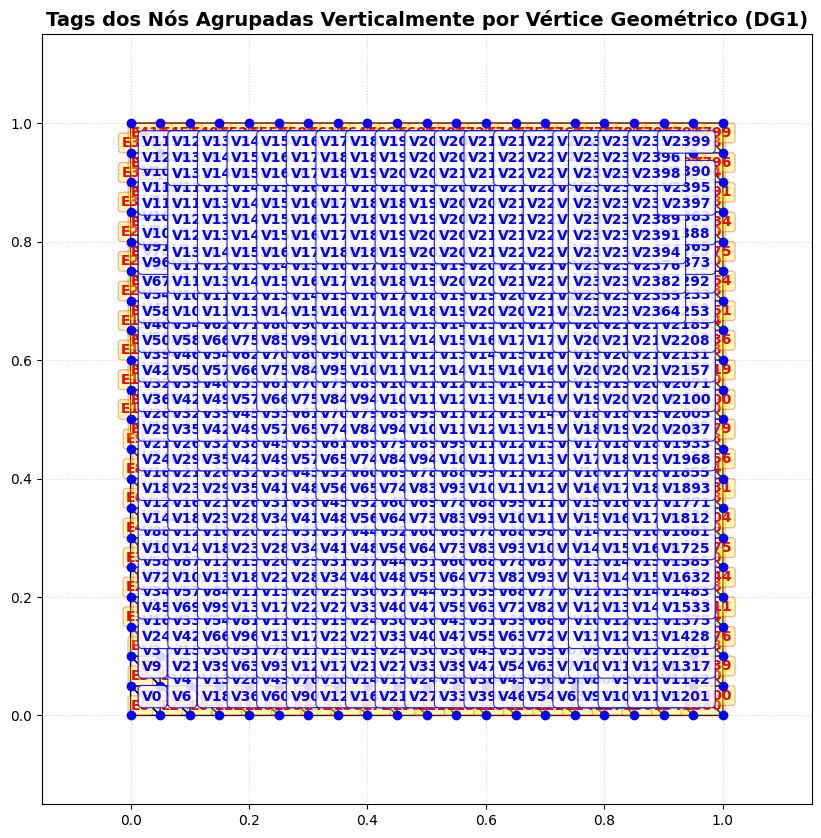

In [166]:
from collections import defaultdict

# Converter listas de nós e elementos para arrays numpy
nodes_arr = np.array(nodes)
elements_arr = np.array(elements)

# Agrupar os índices dos nós por sua coordenada física real (arredondada para evitar imprecisões de ponto flutuante)
coordenadas_unicas = defaultdict(list)
for idx, coord in enumerate(nodes_arr):
    chave = (round(coord[0], 5), round(coord[1], 5))
    coordenadas_unicas[chave].append(idx)

fig, ax = plt.subplots(figsize=(10, 10))

# 1. Desenhar as arestas dos triângulos da malha
for tri in elements_arr:
    pontos = nodes_arr[tri]
    poligono = np.vstack([pontos, pontos[0]])
    ax.plot(poligono[:, 0], poligono[:, 1], color='black', linewidth=1)

# 2. Desenhar as marcações dos nós físicos e agrupar apenas as tags em uma LISTA VERTICAL (usando '\n')
for (x, y), indices in coordenadas_unicas.items():
    # Plotar um único ponto geométrico azul no vértice
    ax.plot(x, y, 'o', color='blue', markersize=6, zorder=5)

    # Construir as tags (V0, V1, V2...) empilhadas verticalmente
    textos_tags = [f"V{idx}" for idx in indices]
    texto_completo = "\n".join(textos_tags)

    # Decidir o posicionamento do texto de acordo com o canto da malha para não cortar a imagem
    offset_x = 0.02
    offset_y = 0.02
    ha, va = 'left', 'bottom'

    if x > 0.8:
        offset_x = -0.02
        ha = 'right'
    if y > 0.8:
        offset_y = -0.02
        va = 'top'

    ax.text(x + offset_x, y + offset_y, texto_completo,
            color="blue", fontsize=10, fontweight="bold",
            ha=ha, va=va, zorder=10,
            bbox=dict(facecolor='white', alpha=0.85, edgecolor='blue', boxstyle='round,pad=0.3', linewidth=0.8))

# 3. Adicionar as numerações dos elementos (E0, E1, ...) de forma sutil no centro de cada triângulo
for i, tri in enumerate(elements_arr):
    coords_triangulo = nodes_arr[tri]
    centro_x = coords_triangulo[:, 0].mean()
    centro_y = coords_triangulo[:, 1].mean()
    ax.text(centro_x, centro_y, f"E{i}",
            color="red", fontsize=10, fontweight="bold",
            ha="center", va="center",
            bbox=dict(facecolor='yellow', alpha=0.3, edgecolor='red', boxstyle='round,pad=0.2'))

ax.set_title("Tags dos Nós Agrupadas Verticalmente por Vértice Geométrico (DG1)", fontsize=14, fontweight="bold")
ax.set_aspect('equal')
ax.set_xlim(-0.15, 1.15)
ax.set_ylim(-0.15, 1.15)
ax.grid(True, linestyle=':', alpha=0.5)
plt.show()

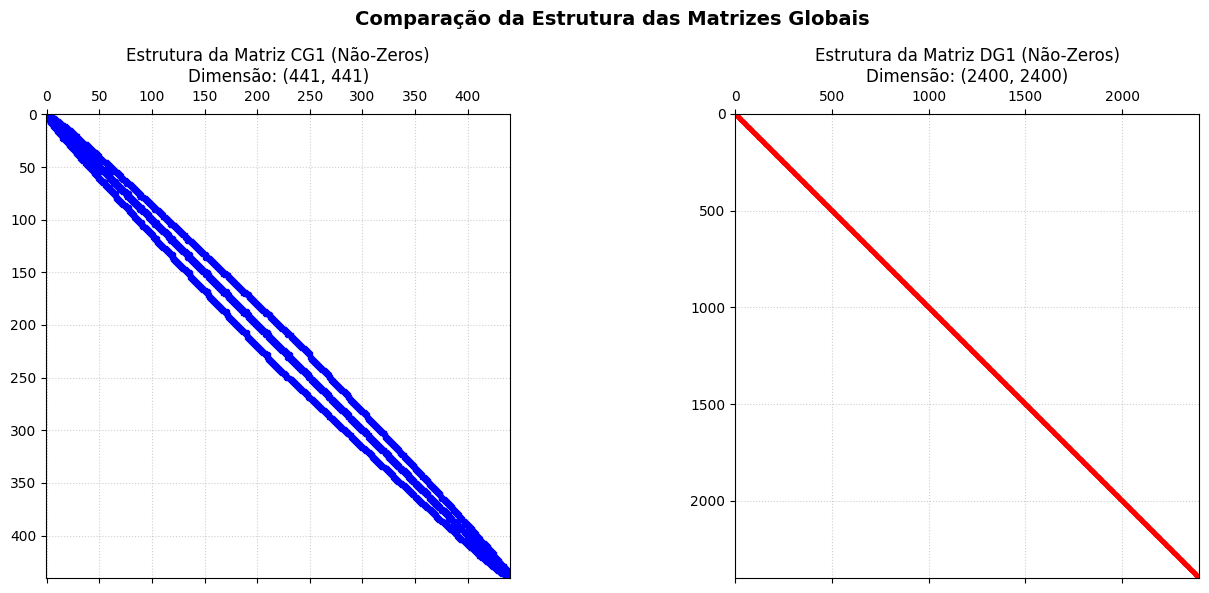

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 70601 stored elements and shape (10201, 10201)>
  Coords	Values
  (0, 0)	2.000016666666669
  (0, 1)	-0.9999916666666676
  (0, 2)	-0.9999916666666676
  (1, 0)	-0.9999916666666676
  (1, 1)	4.000050000000005
  (1, 2)	1.6666666666666688e-05
  (1, 3)	-1.9999833333333352
  (1, 5)	-0.9999916666666676
  (2, 0)	-0.9999916666666676
  (2, 1)	1.6666666666666688e-05
  (2, 2)	4.000050000000005
  (2, 3)	-1.9999833333333352
  (2, 4)	-0.9999916666666676
  (3, 1)	-1.9999833333333352
  (3, 2)	-1.9999833333333352
  (3, 3)	8.00010000000001
  (3, 4)	1.6666666666666688e-05
  (3, 5)	1.6666666666666688e-05
  (3, 6)	-1.9999833333333352
  (3, 7)	-1.9999833333333352
  (4, 2)	-0.9999916666666676
  (4, 3)	1.6666666666666688e-05
  (4, 4)	4.000050000000002
  (4, 6)	-1.9999833333333332
  (4, 8)	-0.9999916666666662
  :	:
  (10196, 10192)	-1.999983333333332
  (10196, 10193)	-1.999983333333332
  (10196, 10195)	1.6666666666666688e-05
  (10196, 10196)	8.00009999

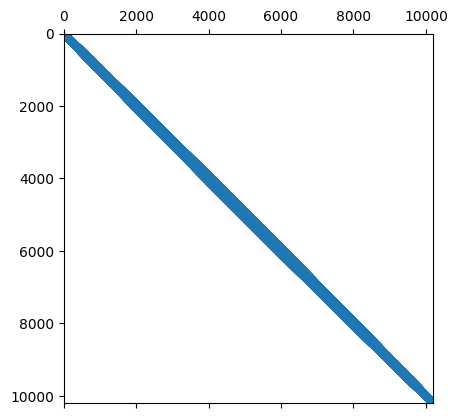

In [167]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# Subplot 1: CG1 Matrix Structure
ax1.spy(Aglob_cg, markersize=3, color='blue')
ax1.set_title(f"Estrutura da Matriz CG1 (Não-Zeros)\nDimensão: {Aglob_cg.shape}", fontsize=12)
ax1.grid(True, linestyle=':', alpha=0.6)

# Subplot 2: DG1 Matrix Structure
ax2.spy(Aglob_dg, markersize=1.5, color='red')
ax2.set_title(f"Estrutura da Matriz DG1 (Não-Zeros)\nDimensão: {Aglob_dg.shape}", fontsize=12)
ax2.grid(True, linestyle=':', alpha=0.6)

plt.suptitle("Comparação da Estrutura das Matrizes Globais", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print(Aglob_h1)
plt.spy(Aglob_h1, markersize=3)
plt.show()

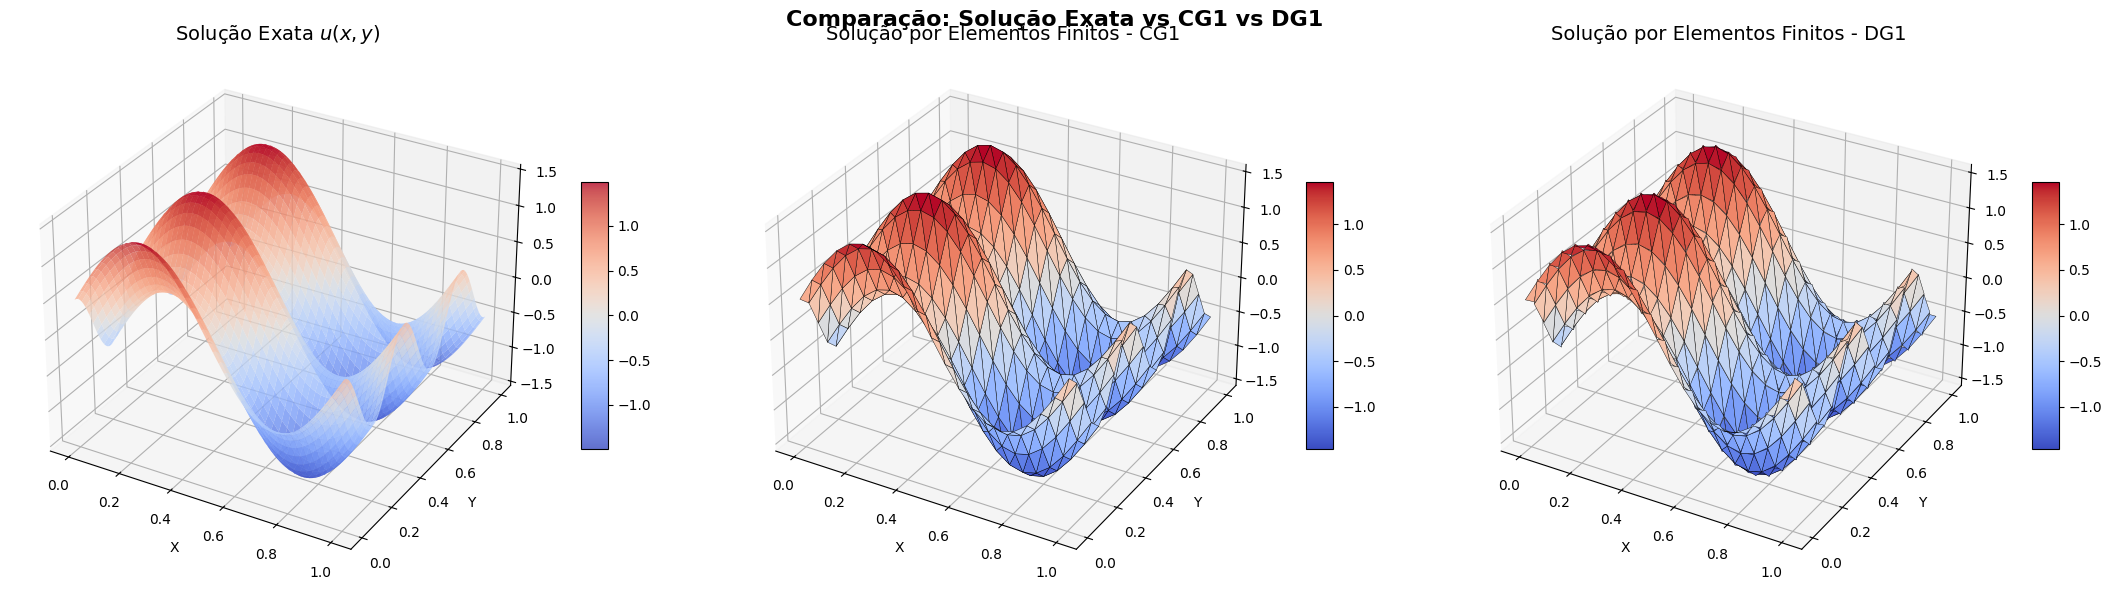

In [168]:
from matplotlib import cm
# Criar uma malha fina para plotar a solução exata contínua
x_fino = np.linspace(0, 1, 100)
y_fino = np.linspace(0, 1, 100)
X_fino, Y_fino = np.meshgrid(x_fino, y_fino)
U_exata = u([X_fino, Y_fino])

# Obter nós e conectividades corretos para cada espaço
nodes_cg_arr, elements_cg_arr = configurar_espaco_aproximacao(nodes_geom, triangulos, type_space="CG1")
nodes_dg_arr, elements_dg_arr = configurar_espaco_aproximacao(nodes_geom, triangulos, type_space="DG1")

# Criar figura com 3 subplots tridimensionais
fig = plt.figure(figsize=(22, 6))

# Subplot 1: Solução Exata
ax1 = fig.add_subplot(1, 3, 1, projection='3d')
surf1 = ax1.plot_surface(X_fino, Y_fino, U_exata, cmap=cm.coolwarm, edgecolor='none', alpha=0.8)
ax1.set_title('Solução Exata $u(x, y)$', fontsize=14)
ax1.set_xlabel('X')
ax1.set_ylabel('Y')
fig.colorbar(surf1, ax=ax1, shrink=0.5, aspect=10)

# Subplot 2: Solução CG1
ax2 = fig.add_subplot(1, 3, 2, projection='3d')
tri_plot_cg = ax2.plot_trisurf(nodes_cg_arr[:, 0], nodes_cg_arr[:, 1], uh_cg, triangles=elements_cg_arr, cmap=cm.coolwarm, edgecolor='k', linewidth=0.3)
ax2.set_title('Solução por Elementos Finitos - CG1', fontsize=14)
ax2.set_xlabel('X')
ax2.set_ylabel('Y')
fig.colorbar(tri_plot_cg, ax=ax2, shrink=0.5, aspect=10)

# Subplot 3: Solução DG1
ax3 = fig.add_subplot(1, 3, 3, projection='3d')
tri_plot_dg = ax3.plot_trisurf(nodes_dg_arr[:, 0], nodes_dg_arr[:, 1], uh_dg, triangles=elements_dg_arr, cmap=cm.coolwarm, edgecolor='k', linewidth=0.3)
ax3.set_title('Solução por Elementos Finitos - DG1', fontsize=14)
ax3.set_xlabel('X')
ax3.set_ylabel('Y')
fig.colorbar(tri_plot_dg, ax=ax3, shrink=0.5, aspect=10)

plt.suptitle("Comparação: Solução Exata vs CG1 vs DG1", fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

Sistema H1 montado e resolvido com sucesso!
Dimensão da matriz H1: (441, 441)


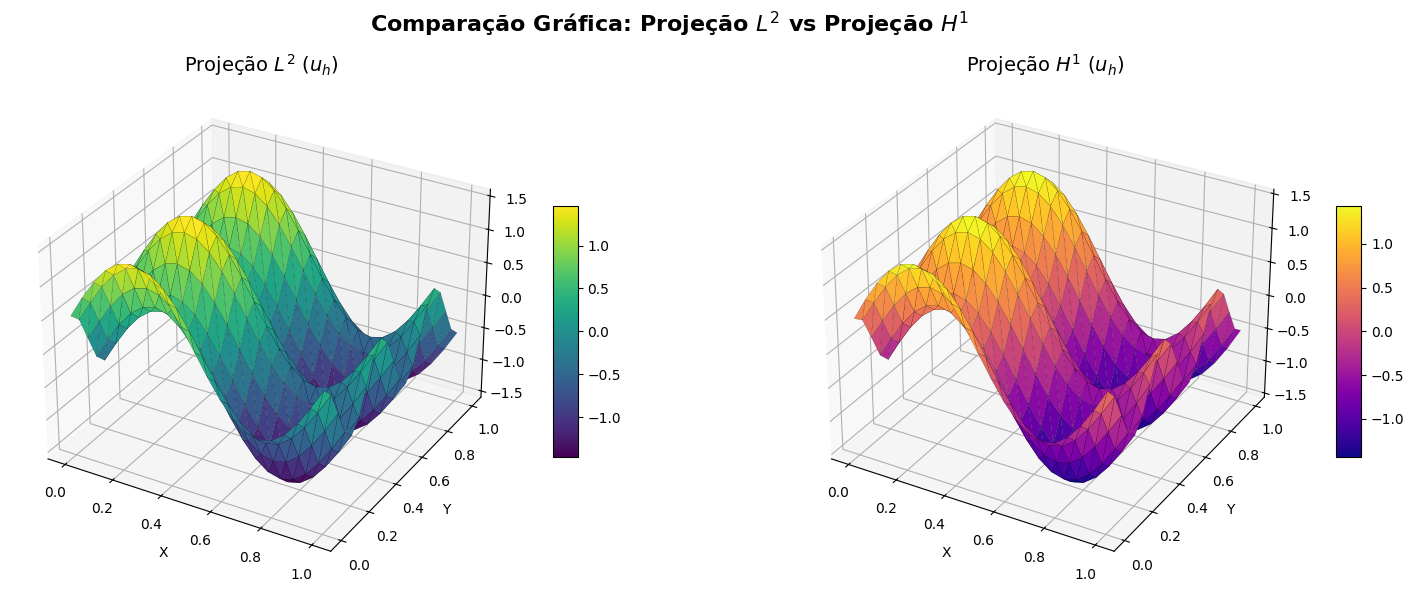

In [169]:
Nx, Ny = 100, 5 # É a quantidade de pontos em cada direção
Lx, Ly = 1.0, 1.0
pontos_gauss, pesos = pontos_pesos_triangulo("cubic")

def u(x):
  return np.sin(2 * np.pi * x[0]) + 0.5 * np.cos(5 * np.pi * x[1])

def grad_u(x):
    # x[0] é o x físico, x[1] é o y físico
    du_dx = 2 * np.pi * np.cos(2 * np.pi * x[0])
    du_dy = -2.5 * np.pi * np.sin(5 * np.pi * x[1])
    return np.array([du_dx, du_dy])

# 3. Escolher o espaço CG1 e configurar
nodes_h1, elements_h1 = configurar_espaco_aproximacao(nodes_geom, triangulos, type_space="CG1")

# 4. Montar e resolver o sistema para a projeção H1
Aglob_h1, RHS_h1 = montar_sistema_H1(nodes_h1, elements_h1, u, grad_u, psi, grad_psi, ordem_quadratura="cubic")
#uh_h1 = np.linalg.solve(Aglob_h1, RHS_h1)
uh_h1 = spsolve(Aglob_h1, RHS_h1)

print("Sistema H1 montado e resolvido com sucesso!")
print(f"Dimensão da matriz H1: {Aglob_h1.shape}")

# 5. Visualização Comparativa: Projeção L2 vs Projeção H1
nodes_arr = np.array(nodes_h1)
fig = plt.figure(figsize=(16, 6))

# Subplot 1: Projeção L2 (calculada anteriormente)
ax1 = fig.add_subplot(1, 2, 1, projection='3d')
surf1 = ax1.plot_trisurf(nodes_arr[:, 0], nodes_arr[:, 1], uh_cg, triangles=elements_h1, cmap='viridis', edgecolor='k', linewidth=0.1)
ax1.set_title('Projeção $L^2$ ($u_h$)', fontsize=14)
ax1.set_xlabel('X')
ax1.set_ylabel('Y')
fig.colorbar(surf1, ax=ax1, shrink=0.5, aspect=10)

# Subplot 2: Projeção H1
ax2 = fig.add_subplot(1, 2, 2, projection='3d')
surf2 = ax2.plot_trisurf(nodes_arr[:, 0], nodes_arr[:, 1], uh_h1, triangles=elements_h1, cmap='plasma', edgecolor='k', linewidth=0.1)
ax2.set_title('Projeção $H^1$ ($u_h$)', fontsize=14)
ax2.set_xlabel('X')
ax2.set_ylabel('Y')
fig.colorbar(surf2, ax=ax2, shrink=0.5, aspect=10)

plt.suptitle("Comparação Gráfica: Projeção $L^2$ vs Projeção $H^1$", fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

Sistema H1 montado e resolvido com sucesso!
Dimensão da matriz H1: (441, 441)


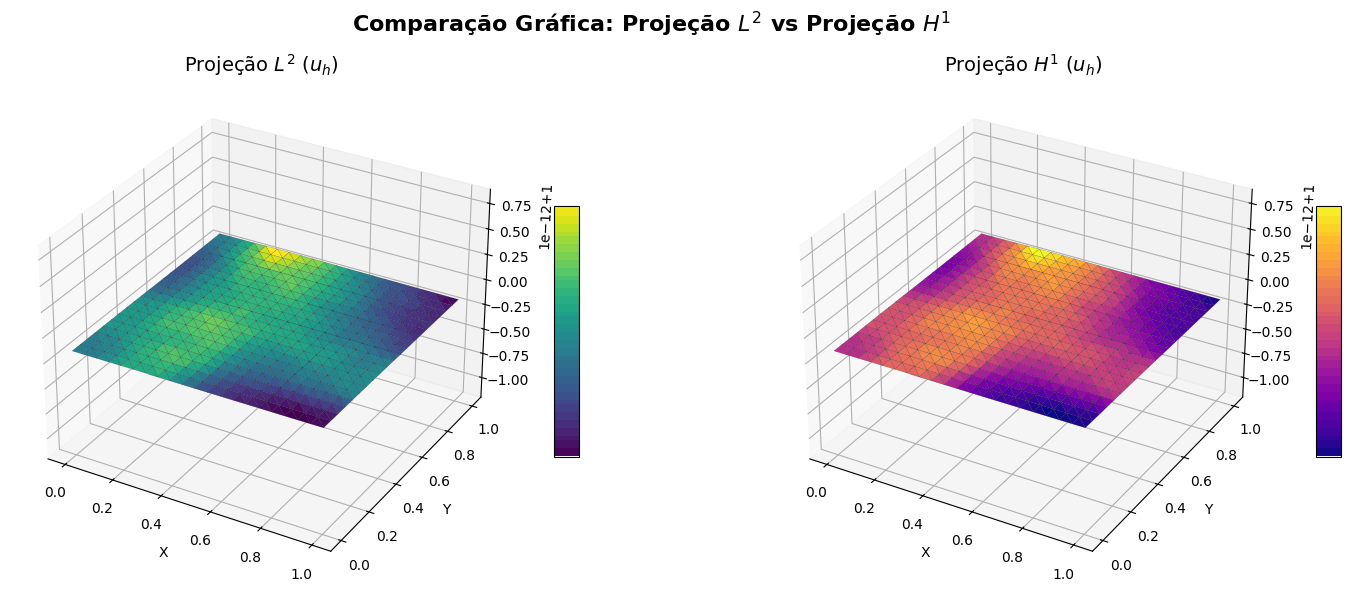

In [170]:
Nx, Ny = 20, 20 # É a quantidade de pontos em cada direção
Lx, Ly = 1.0, 1.0
pontos_gauss, pesos = pontos_pesos_triangulo("cubic")

def u_caso1(x):
    return 1.0

def grad_u_caso1(x):
    return np.array([0.0, 0.0])

nodes_cg, elements_cg = configurar_espaco_aproximacao(
    nodes_geom, triangulos, type_space="CG1"
)

A_caso1, b_caso1 = montar_sistema_H1(
    nodes_cg,
    elements_cg,
    u_caso1,
    grad_u_caso1,
    psi,
    grad_psi,
    ordem_quadratura="cubic"
)

u_h_caso1 = spsolve(A_caso1, b_caso1)

print("Sistema H1 montado e resolvido com sucesso!")
print(f"Dimensão da matriz H1: {A_caso1.shape}")

# 5. Visualização Comparativa: Projeção L2 vs Projeção H1
nodes_arr = np.array(nodes_cg)
fig = plt.figure(figsize=(16, 6))

# Subplot 1: Projeção L2 (calculada anteriormente)
ax1 = fig.add_subplot(1, 2, 1, projection='3d')
surf1 = ax1.plot_trisurf(nodes_arr[:, 0], nodes_arr[:, 1], u_h_caso1 , triangles=elements_cg, cmap='viridis', edgecolor='k', linewidth=0.1)
ax1.set_title('Projeção $L^2$ ($u_h$)', fontsize=14)
ax1.set_xlabel('X')
ax1.set_ylabel('Y')
fig.colorbar(surf1, ax=ax1, shrink=0.5, aspect=10)

# Subplot 2: Projeção H1
ax2 = fig.add_subplot(1, 2, 2, projection='3d')
surf2 = ax2.plot_trisurf(nodes_arr[:, 0], nodes_arr[:, 1], u_h_caso1, triangles=elements_cg, cmap='plasma', edgecolor='k', linewidth=0.1)
ax2.set_title('Projeção $H^1$ ($u_h$)', fontsize=14)
ax2.set_xlabel('X')
ax2.set_ylabel('Y')
fig.colorbar(surf2, ax=ax2, shrink=0.5, aspect=10)

plt.suptitle("Comparação Gráfica: Projeção $L^2$ vs Projeção $H^1$", fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

In [171]:
from scipy.sparse import coo_matrix
from scipy.sparse.linalg import spsolve


def resolver_mef(
    nodes,
    elements,
    psi,
    grad_psi,
    forma_bilinear_local,
    forma_linear_local,
    dirichlet=None,
    ordem_quadratura="cubic"
):
    """
    Monta e resolve A u = b para elementos triangulares P1.

    forma_bilinear_local(x, phi_trial, grad_trial, phi_test, grad_test)
        Retorna o integrando local de a(u, v).

    forma_linear_local(x, phi_test, grad_test)
        Retorna o integrando local de l(v).

    dirichlet:
        Dicionário {grau_de_liberdade: valor_prescrito}.
        Exemplo: {0: 0.0, 1: 0.0, ...}

    Retorna:
        uh: solução nodal;
        A: matriz esparsa montada antes de impor Dirichlet;
        b: vetor montado antes de impor Dirichlet.
    """
    pontos_gauss, pesos = pontos_pesos_triangulo(ordem_quadratura)

    nnodes = len(nodes)
    nloc = len(psi)

    linhas = []
    colunas = []
    valores = []
    b = np.zeros(nnodes)

    for m, elemento in enumerate(elements):
        v0 = nodes[elemento[0]]
        Bk = getBk(element=elemento, nodes=nodes)

        det_jac = abs(np.linalg.det(Bk))
        invBk_T = np.linalg.inv(Bk.T)

        ae = np.zeros((nloc, nloc))
        be = np.zeros(nloc)

        for ponto, peso in zip(pontos_gauss, pesos):
            xi, eta = ponto[:2]

            x_fisico = v0 + Bk @ np.array([xi, eta])

            phi = [psi[r](xi, eta) for r in range(nloc)]
            grad_phi = [
                invBk_T @ grad_psi[r](xi, eta)
                for r in range(nloc)
            ]

            # Os pesos da sua tabela somam 1.
            # A área do triângulo de referência é 1/2.
            fator = 0.5 * det_jac * peso

            for i in range(nloc):
                be[i] += fator * forma_linear_local(
                    x_fisico, phi[i], grad_phi[i]
                )

                for j in range(nloc):
                    # j: função de tentativa; i: função de teste
                    ae[i, j] += fator * forma_bilinear_local(
                        x_fisico,
                        phi[j], grad_phi[j],
                        phi[i], grad_phi[i]
                    )

        # Espalhamento das contribuições locais para o sistema global
        for i in range(nloc):
            I = elemento[i]
            b[I] += be[i]

            for j in range(nloc):
                J = elemento[j]
                linhas.append(I)
                colunas.append(J)
                valores.append(ae[i, j])

    A = coo_matrix(
        (valores, (linhas, colunas)),
        shape=(nnodes, nnodes)
    ).tocsr()

    A.eliminate_zeros()

    # Impõe as condições de Dirichlet pelo sistema reduzido.
    if dirichlet:
        dofs_fixos = np.array(sorted(dirichlet), dtype=int)
        valores_fixos = np.array(
            [dirichlet[i] for i in dofs_fixos],
            dtype=float
        )

        todos_dofs = np.arange(nnodes)
        dofs_livres = np.setdiff1d(todos_dofs, dofs_fixos)

        uh = np.zeros(nnodes)
        uh[dofs_fixos] = valores_fixos

        A_ll = A[dofs_livres, :][:, dofs_livres]
        A_ld = A[dofs_livres, :][:, dofs_fixos]

        b_l = b[dofs_livres] - A_ld @ valores_fixos
        uh[dofs_livres] = spsolve(A_ll, b_l)
    else:
        uh = spsolve(A, b)

    return uh, A, b

In [172]:
def bilinear_caso2(x, phi_trial, grad_trial, phi_test, grad_test):
    return np.dot(grad_trial, grad_test) + phi_trial * phi_test


def linear_caso2(x, phi_test, grad_test):
    return phi_test

In [173]:
tol = 1e-12

nos_contorno = np.flatnonzero(
    np.isclose(nodes[:, 0], 0.0, atol=tol, rtol=0.0)
    | np.isclose(nodes[:, 0], 1.0, atol=tol, rtol=0.0)
    | np.isclose(nodes[:, 1], 0.0, atol=tol, rtol=0.0)
    | np.isclose(nodes[:, 1], 1.0, atol=tol, rtol=0.0)
)

bc_dirichlet = {int(i): 0.0 for i in nos_contorno}

In [178]:
nodes_geom, triangulos = gerar_malha_2d(
    lx=1.0,
    ly=1.0,
    nx=8,
    ny=8
)

nodes, elements = configurar_espaco_aproximacao(
    nodes_geom,
    triangulos,
    type_space="CG1"
)

nos_contorno = np.flatnonzero(
    np.isclose(nodes[:, 0], 0.0, atol=tol, rtol=0.0)
    | np.isclose(nodes[:, 0], 1.0, atol=tol, rtol=0.0)
    | np.isclose(nodes[:, 1], 0.0, atol=tol, rtol=0.0)
    | np.isclose(nodes[:, 1], 1.0, atol=tol, rtol=0.0)
)

bc_dirichlet = {int(i): 0.0 for i in nos_contorno}

uh, A, b = resolver_mef(
    nodes=nodes,
    elements=elements,
    psi=psi,
    grad_psi=grad_psi,
    forma_bilinear_local=bilinear_caso2,
    forma_linear_local=linear_caso2,
    dirichlet=bc_dirichlet,
    ordem_quadratura="cubic"
)

print("Menor valor nodal:", uh.min())
print("Maior valor nodal:", uh.max())
print("Nós de fronteira:", uh[nos_contorno])

Menor valor nodal: 0.0
Maior valor nodal: 0.06909699631611668
Nós de fronteira: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0.]


Sistema H1 montado e resolvido com sucesso!
Dimensão da matriz H1: (441, 441)


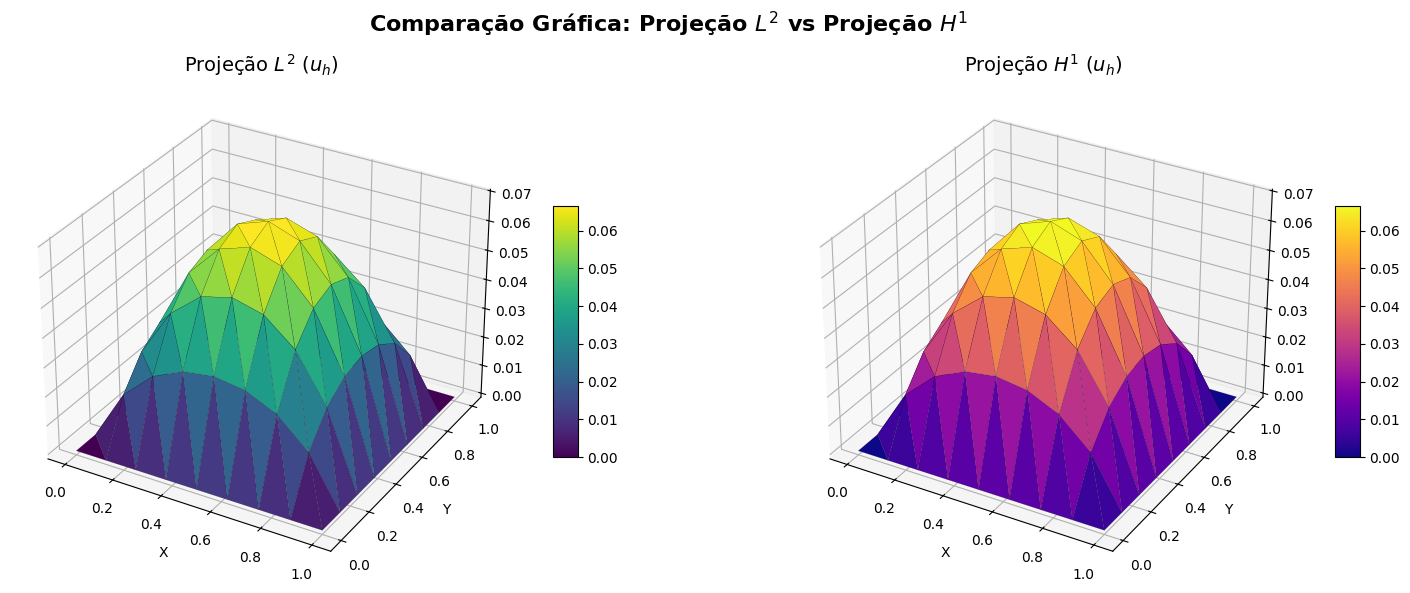

In [179]:
print("Sistema H1 montado e resolvido com sucesso!")
print(f"Dimensão da matriz H1: {A_caso1.shape}")

#uh, A, b

# 5. Visualização Comparativa: Projeção L2 vs Projeção H1
nodes_arr = np.array(nodes)
fig = plt.figure(figsize=(16, 6))

# Subplot 1: Projeção L2 (calculada anteriormente)
ax1   = fig.add_subplot(1, 2, 1, projection='3d')
surf1 = ax1.plot_trisurf(nodes_arr[:, 0], nodes_arr[:, 1], uh , triangles=elements, cmap='viridis', edgecolor='k', linewidth=0.1)
ax1.set_title('Projeção $L^2$ ($u_h$)', fontsize=14)
ax1.set_xlabel('X')
ax1.set_ylabel('Y')
fig.colorbar(surf1, ax=ax1, shrink=0.5, aspect=10)

# Subplot 2: Projeção H1
ax2 = fig.add_subplot(1, 2, 2, projection='3d')
surf2 = ax2.plot_trisurf(nodes_arr[:, 0], nodes_arr[:, 1], uh, triangles=elements, cmap='plasma', edgecolor='k', linewidth=0.1)
ax2.set_title('Projeção $H^1$ ($u_h$)', fontsize=14)
ax2.set_xlabel('X')
ax2.set_ylabel('Y')
fig.colorbar(surf2, ax=ax2, shrink=0.5, aspect=10)

plt.suptitle("Comparação Gráfica: Projeção $L^2$ vs Projeção $H^1$", fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

In [180]:
def bilinear_caso3(x, phi_trial, grad_trial, phi_test, grad_test):
    x_coord, y_coord = x

    mu = 1.0 + x_coord**2 + y_coord**2
    sigma = x_coord * y_coord

    return (
        mu * np.dot(grad_trial, grad_test)
        + sigma * phi_trial * phi_test
    )


def linear_caso3(x, phi_test, grad_test):
    f = x[0] + x[1]
    return f * phi_test
def bilinear_caso3(x, phi_trial, grad_trial, phi_test, grad_test):
    x_coord, y_coord = x

    mu = 1.0 + x_coord**2 + y_coord**2
    sigma = x_coord * y_coord

    return (
        mu * np.dot(grad_trial, grad_test)
        + sigma * phi_trial * phi_test
    )


def linear_caso3(x, phi_test, grad_test):
    f = x[0] + x[1]
    return f * phi_test


tol = 1e-12
bc_dirichlet = {}

for i, (x, y) in enumerate(nodes):
    esta_na_esquerda = np.isclose(x, 0.0, atol=tol, rtol=0.0)
    esta_em_baixo = np.isclose(y, 0.0, atol=tol, rtol=0.0)

    if esta_na_esquerda:
        bc_dirichlet[i] = y * (1.0 - y)
    elif esta_em_baixo:
        bc_dirichlet[i] = x * (1.0 - x)

uh_caso3, A_caso3, b_caso3 = resolver_mef(
    nodes=nodes,
    elements=elements,
    psi=psi,
    grad_psi=grad_psi,
    forma_bilinear_local=bilinear_caso3,
    forma_linear_local=linear_caso3,
    dirichlet=bc_dirichlet,
    ordem_quadratura="quintic"
)

print(uh_caso3[list(bc_dirichlet)])

[0.       0.109375 0.109375 0.1875   0.1875   0.234375 0.234375 0.25
 0.25     0.234375 0.234375 0.1875   0.1875   0.109375 0.109375 0.
 0.      ]


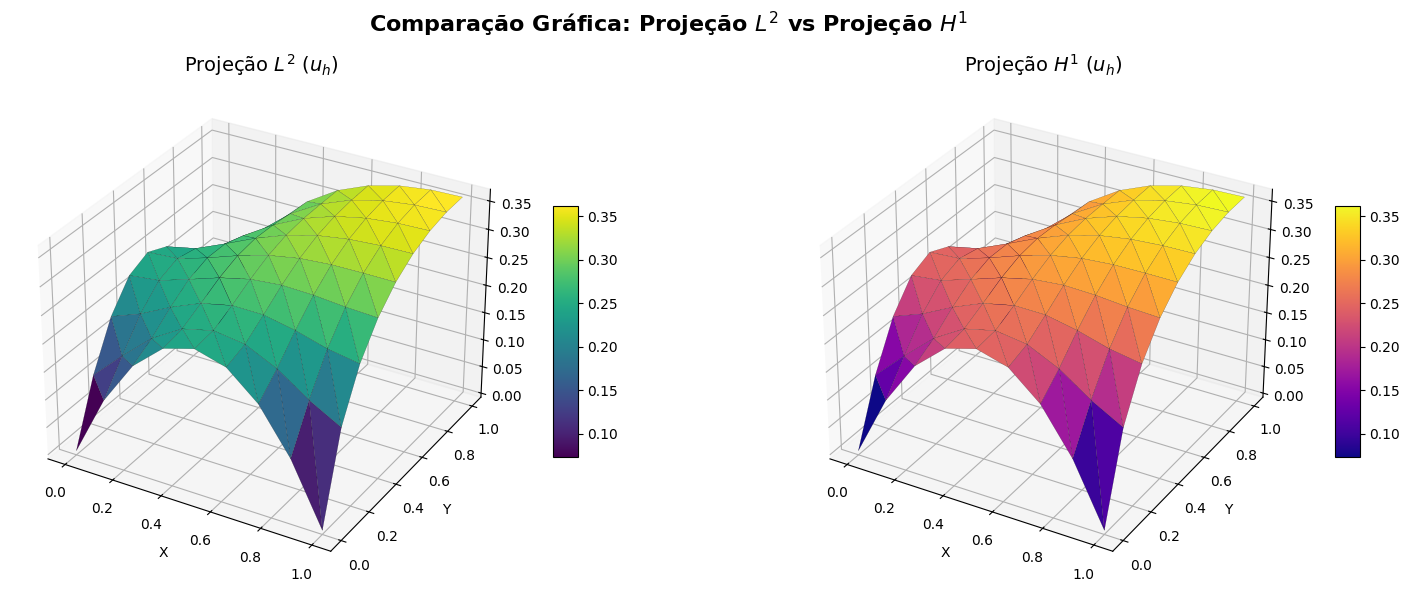

In [181]:
nodes_arr = np.array(nodes)
fig = plt.figure(figsize=(16, 6))

# Subplot 1: Projeção L2 (calculada anteriormente)
ax1   = fig.add_subplot(1, 2, 1, projection='3d')
surf1 = ax1.plot_trisurf(nodes_arr[:, 0], nodes_arr[:, 1], uh_caso3 , triangles=elements, cmap='viridis', edgecolor='k', linewidth=0.1)
ax1.set_title('Projeção $L^2$ ($u_h$)', fontsize=14)
ax1.set_xlabel('X')
ax1.set_ylabel('Y')
fig.colorbar(surf1, ax=ax1, shrink=0.5, aspect=10)

# Subplot 2: Projeção H1
ax2 = fig.add_subplot(1, 2, 2, projection='3d')
surf2 = ax2.plot_trisurf(nodes_arr[:, 0], nodes_arr[:, 1],uh_caso3 , triangles=elements, cmap='plasma', edgecolor='k', linewidth=0.1)
ax2.set_title('Projeção $H^1$ ($u_h$)', fontsize=14)
ax2.set_xlabel('X')
ax2.set_ylabel('Y')
fig.colorbar(surf2, ax=ax2, shrink=0.5, aspect=10)

plt.suptitle("Comparação Gráfica: Projeção $L^2$ vs Projeção $H^1$", fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()